# 02 · Exploración de datos

> **Flujo del proyecto** (diagrama del profesor)
> `01 Limpieza` → `02 Exploración` → `03 Creación de variables` → `04 Preparación (split temporal + folds)` →
> `05a Logística` · `05b Random Forest` · `05c XGBoost` · `05d Red neuronal` (cada uno: selección de variables → hiperparámetros) →
> `06 Selección del mejor modelo y prueba final en test`


    **Entrada:** `datos/interim/` · **Salida:** figuras en `reportes/figuras/` y `reportes/metricas/eda.json`.

    **Regla anti-fuga:** la exploración descriptiva usa todo el periodo, pero cualquier análisis **contra el label que pueda influir
    en decisiones de modelado** se hace sólo con el periodo de entrenamiento (compras antes de `FECHA_CORTE_TEST`).
    El test (mayo–agosto 2018) no se mira aquí.

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config, viz
viz.aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

In [2]:
t = {n: pd.read_parquet(config.DATOS_INTERIM / f"{n}.parquet")
     for n in ["orders", "customers", "sellers", "items", "products", "payments", "reviews"]}
orders = t["orders"]
orders = orders[orders["order_purchase_timestamp"] >= config.FECHA_INICIO_MODELO].copy()
corte = pd.Timestamp(config.FECHA_CORTE_TEST)
es_train = orders["order_purchase_timestamp"] < corte
print(f"Pedidos en el periodo de estudio: {len(orders):,} | tasa de retraso global: {orders['delivery_late'].mean():.2%}")
eda = {"pedidos": int(len(orders)), "tasa_tardios": float(orders["delivery_late"].mean())}

Pedidos en el periodo de estudio: 96,201 | tasa de retraso global: 6.79%


## 1. El costo de llegar tarde (caso de negocio)
¿Por qué importa predecir retrasos? Comparamos la calificación que deja el cliente en pedidos tardíos vs. a tiempo.

,promedio,pct_1_2_estrellas,pct_5_estrellas
A tiempo,4.29,9.21,62.23
Tardío,2.27,62.35,16.54


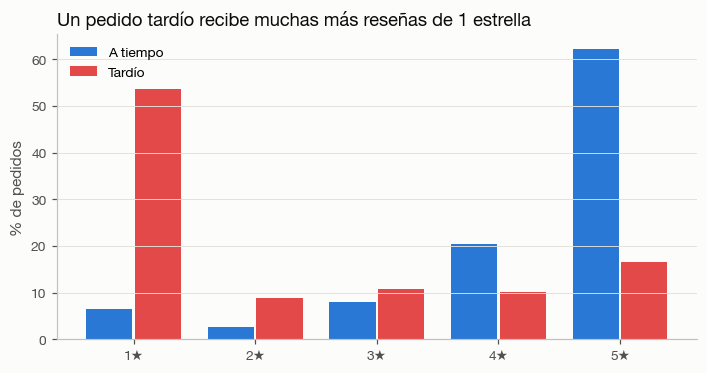

In [3]:
rev = t["reviews"].groupby("order_id")["review_score"].mean().rename("score")
o_rev = orders.join(rev, on="order_id").dropna(subset=["score"])
resumen_rev = o_rev.groupby("delivery_late")["score"].agg(
    promedio="mean", pct_1_2_estrellas=lambda s: (s <= 2).mean() * 100, pct_5_estrellas=lambda s: (s == 5).mean() * 100)
resumen_rev.index = ["A tiempo", "Tardío"]
display(resumen_rev.round(2))

dist = (o_rev.assign(estrellas=o_rev["score"].round().astype(int))
        .groupby("delivery_late")["estrellas"].value_counts(normalize=True).mul(100).unstack(0).sort_index())
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(1, 6)
ax.bar(x - 0.2, dist[0], width=0.38, color=viz.A_TIEMPO, label="A tiempo")
ax.bar(x + 0.2, dist[1], width=0.38, color=viz.TARDIO, label="Tardío")
ax.set_xticks(x, [f"{i}★" for i in x]); ax.set_ylabel("% de pedidos")
ax.set_title("Un pedido tardío recibe muchas más reseñas de 1 estrella")
ax.legend(); ax.grid(axis="x", visible=False)
viz.guardar(fig, "eda_reviews"); plt.show()

eda["reviews"] = {
    "score_a_tiempo": float(resumen_rev.loc["A tiempo", "promedio"]),
    "score_tardio": float(resumen_rev.loc["Tardío", "promedio"]),
    "pct_1_2_a_tiempo": float(resumen_rev.loc["A tiempo", "pct_1_2_estrellas"]),
    "pct_1_2_tardio": float(resumen_rev.loc["Tardío", "pct_1_2_estrellas"]),
    "pct_5_a_tiempo": float(resumen_rev.loc["A tiempo", "pct_5_estrellas"]),
    "pct_5_tardio": float(resumen_rev.loc["Tardío", "pct_5_estrellas"]),
    "dist_estrellas": {"a_tiempo": dist[0].round(2).tolist(), "tardio": dist[1].round(2).tolist()},
}

## 2. Los retrasos llegan en oleadas
La tasa de retraso cambia mucho en el tiempo (Black Friday 2017, febrero–marzo 2018). Esto justifica:
(a) un split **temporal**, (b) variables de **carga reciente** del sistema y (c) no usar el mes como variable.

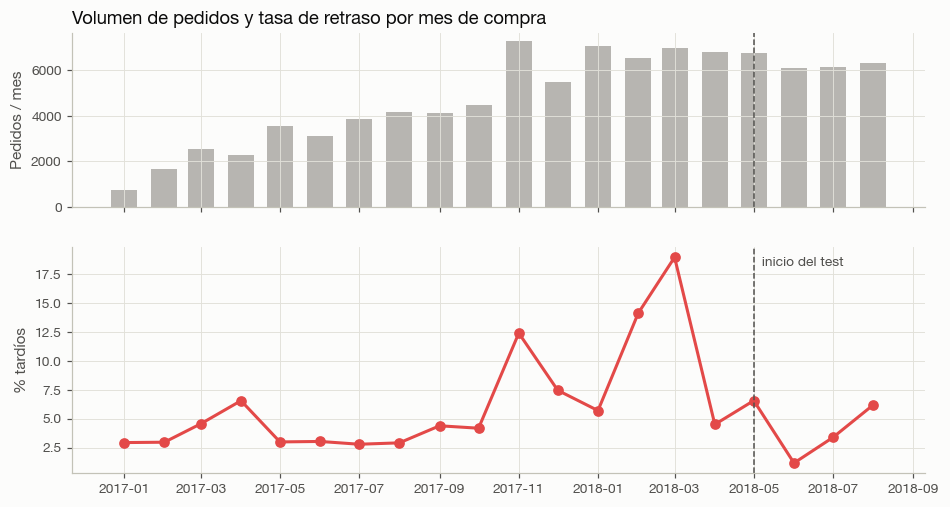

In [4]:
mensual = (orders.set_index("order_purchase_timestamp")["delivery_late"]
           .resample("MS").agg(["size", "mean"]).rename(columns={"size": "pedidos", "mean": "tasa"}))
fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
axes[0].bar(mensual.index, mensual["pedidos"], width=20, color=viz.NEUTRO, alpha=0.6)
axes[0].set_ylabel("Pedidos / mes"); axes[0].set_title("Volumen de pedidos y tasa de retraso por mes de compra")
axes[1].plot(mensual.index, mensual["tasa"] * 100, color=viz.TARDIO, marker="o")
axes[1].set_ylabel("% tardíos")
for ax in axes:
    ax.axvline(corte, color=viz.TINTA_2, linestyle="--", linewidth=1)
axes[1].text(corte, axes[1].get_ylim()[1] * 0.92, "  inicio del test", color=viz.TINTA_2, fontsize=9)
viz.guardar(fig, "eda_tasa_mensual"); plt.show()

eda["mensual"] = {"mes": [d.strftime("%Y-%m") for d in mensual.index],
                  "pedidos": mensual["pedidos"].astype(int).tolist(),
                  "tasa": mensual["tasa"].round(4).tolist()}

## 3. La fecha estimada ya incluye el riesgo de retraso 
La mayoría de los pedidos llega **antes** de lo prometido: predecir retrasos sobre esa estimación es un problema difícil
(la estimación de Olist ya absorbe buena parte del riesgo).

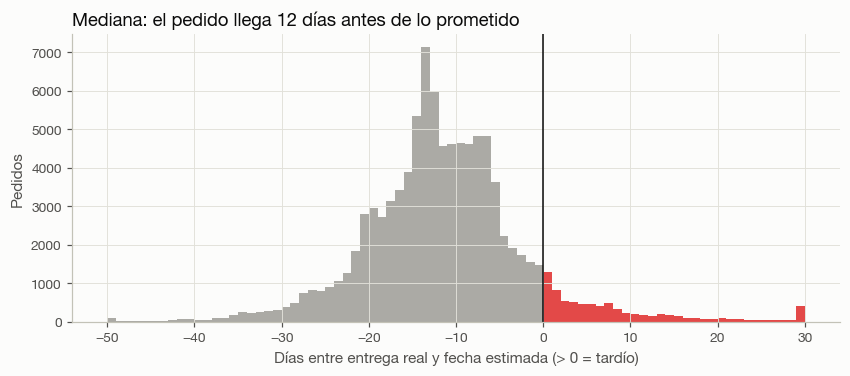

In [5]:
d = orders["dias_retraso_entrega"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(d.clip(-50, 30), bins=80, color=viz.NEUTRO, alpha=0.7)
ax.hist(d[d > 0].clip(-50, 30), bins=np.linspace(0, 30, 31), color=viz.TARDIO)
ax.axvline(0, color=viz.TINTA, linewidth=1)
ax.set_xlabel("Días entre entrega real y fecha estimada (> 0 = tardío)"); ax.set_ylabel("Pedidos")
ax.set_title(f"Mediana: el pedido llega {abs(d.median()):.0f} días antes de lo prometido")
viz.guardar(fig, "eda_dias_retraso"); plt.show()
eda["dias_antes_mediana"] = float(-d.median())
eda["dias_retraso_mediana_tardios"] = float(d[d > 0].median())

## 4. Outliers (método IQR)
**No** eliminamos outliers: los pedidos extremos (muy pesados, muy lejanos) son justamente los que más se retrasan.
Los modelos de árboles son robustos a ellos y la logística/red usan escalado dentro de cada fold.

In [6]:
def pct_outliers(serie):
    s = serie.dropna(); q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return pd.Series({"% bajo límite": (s < q1 - 1.5 * iqr).mean() * 100, "% sobre límite": (s > q3 + 1.5 * iqr).mean() * 100})

tabla = pd.DataFrame({
    "dias_retraso_entrega": pct_outliers(orders["dias_retraso_entrega"]),
    "price": pct_outliers(t["items"]["price"]), "freight_value": pct_outliers(t["items"]["freight_value"]),
    "payment_value": pct_outliers(t["payments"]["payment_value"]),
    "product_weight_g": pct_outliers(t["products"]["product_weight_g"]),
}).T.round(2)
display(tabla)

,% bajo límite,% sobre límite
dias_retraso_entrega,1.93,2.94
price,0.00,7.48
freight_value,0.46,10.31
payment_value,0.00,7.68
product_weight_g,0.00,13.81


## 5. Geografía del retraso (sólo periodo de entrenamiento)
Este análisis sí es contra el label → sólo con compras anteriores al inicio del test.

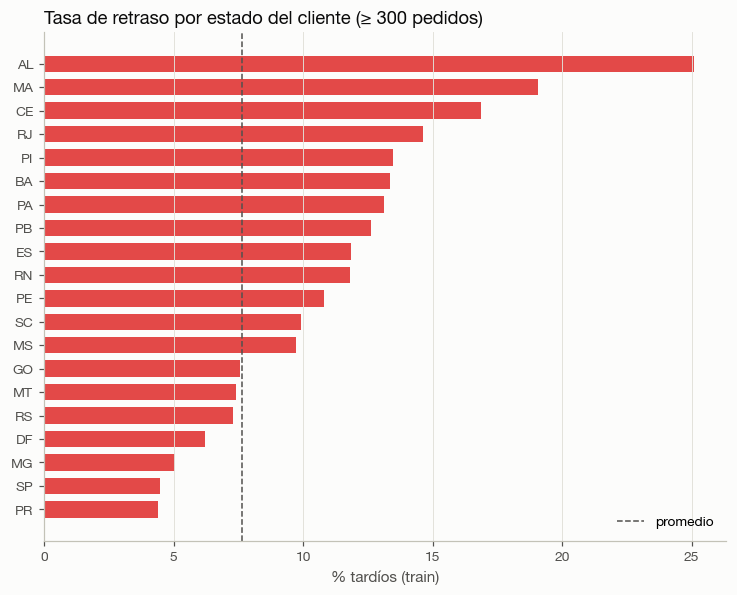

In [7]:
o_train = orders[es_train].merge(t["customers"][["customer_id", "customer_state"]], on="customer_id", how="left")
por_estado = o_train.groupby("customer_state")["delivery_late"].agg(pedidos="size", tasa="mean")
por_estado = por_estado[por_estado["pedidos"] >= 300].sort_values("tasa")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(por_estado.index, por_estado["tasa"] * 100, color=viz.TARDIO, height=0.7)
ax.axvline(o_train["delivery_late"].mean() * 100, color=viz.TINTA_2, linestyle="--", linewidth=1, label="promedio")
ax.set_xlabel("% tardíos (train)"); ax.set_title("Tasa de retraso por estado del cliente (≥ 300 pedidos)")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
viz.guardar(fig, "eda_estados"); plt.show()
eda["estados_train"] = {k: round(float(v), 4) for k, v in por_estado["tasa"].items()}

## 6. Precio y flete

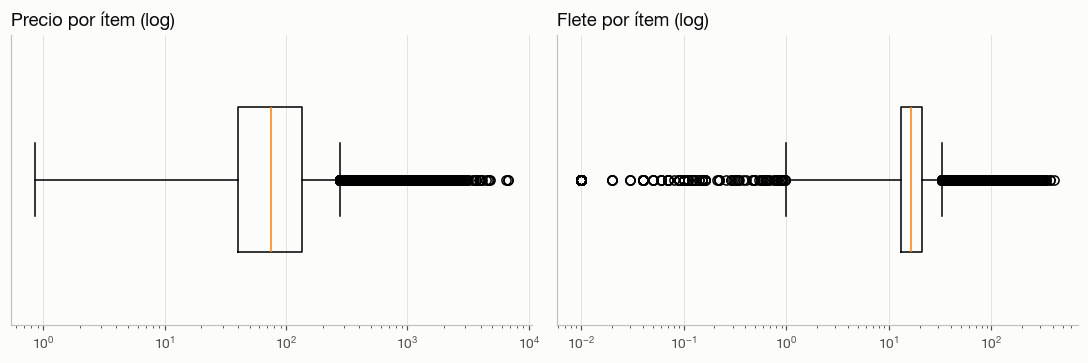

Métricas de exploración guardadas.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].boxplot(t["items"]["price"], vert=False, widths=0.5); axes[0].set_xscale("log"); axes[0].set_title("Precio por ítem (log)")
axes[1].boxplot(t["items"]["freight_value"] + 0.01, vert=False, widths=0.5); axes[1].set_xscale("log"); axes[1].set_title("Flete por ítem (log)")
for ax in axes: ax.set_yticks([])
plt.tight_layout(); plt.show()
(config.METRICAS / "eda.json").write_text(json.dumps(eda, indent=2, ensure_ascii=False))
print("Métricas de exploración guardadas.")